In [4]:

!pip install -q datasets pandas scikit-learn matplotlib


In [5]:

from datasets import load_dataset
import pandas as pd

dataset = load_dataset(
    "zefang-liu/phishing-email-dataset"
)

df = dataset["train"].to_pandas()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


README.md:   0%|          | 0.00/616 [00:00<?, ?B/s]

Phishing_Email.csv: reconstructing file:   0%|          |  0.00B / 52.0MB            

Phishing_Email.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/18650 [00:00<?, ? examples/s]

Dataset loaded successfully!
Dataset shape: (18650, 3)
Columns: ['Unnamed: 0', 'Email Text', 'Email Type']


,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email


In [6]:

df = df[["Email Text", "Email Type"]].copy()

df = df.rename(columns={
    "Email Text": "text",
    "Email Type": "label"
})

df["label"] = df["label"].map({
    "Safe Email": 0,
    "Phishing Email": 1
})

df = df.dropna(subset=["text", "label"])
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]

df = df.drop_duplicates(subset=["text"])
df["label"] = df["label"].astype(int)

print("Clean dataset shape:", df.shape)
print(df["label"].value_counts())

display(df.head())


Clean dataset shape: (17522, 2)
label
0    10978
1     6544
Name: count, dtype: int64


,text,label
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",0
1,the other side of * galicismos * * galicismo *...,0
2,re : equistar deal tickets are you still avail...,0
3,Hello I am your hot lil horny toy.\n I am t...,1
4,software at incredibly low prices ( 86 % lower...,1


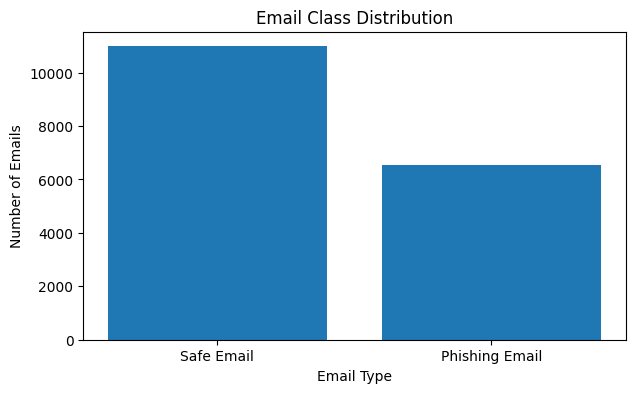

In [7]:

import matplotlib.pyplot as plt

counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(7, 4))

plt.bar(
    ["Safe Email", "Phishing Email"],
    [counts.get(0, 0), counts.get(1, 0)]
)

plt.title("Email Class Distribution")
plt.xlabel("Email Type")
plt.ylabel("Number of Emails")
plt.show()


In [8]:

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training emails:", len(train_df))
print("Validation emails:", len(val_df))
print("Testing emails:", len(test_df))


Training emails: 12265
Validation emails: 2628
Testing emails: 2629


In [9]:

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train = vectorizer.fit_transform(
    train_df["text"]
)

X_val = vectorizer.transform(
    val_df["text"]
)

X_test = vectorizer.transform(
    test_df["text"]
)

y_train = train_df["label"]
y_val = val_df["label"]
y_test = test_df["label"]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)


Training shape: (12265, 10000)
Validation shape: (2628, 10000)
Testing shape: (2629, 10000)


In [10]:

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [11]:

from sklearn.metrics import classification_report

y_pred = model.predict(X_val)

print(
    classification_report(
        y_val,
        y_pred,
        target_names=["Safe Email", "Phishing Email"]
    )
)


                precision    recall  f1-score   support

    Safe Email       0.99      0.98      0.98      1647
Phishing Email       0.96      0.98      0.97       981

      accuracy                           0.98      2628
     macro avg       0.98      0.98      0.98      2628
  weighted avg       0.98      0.98      0.98      2628



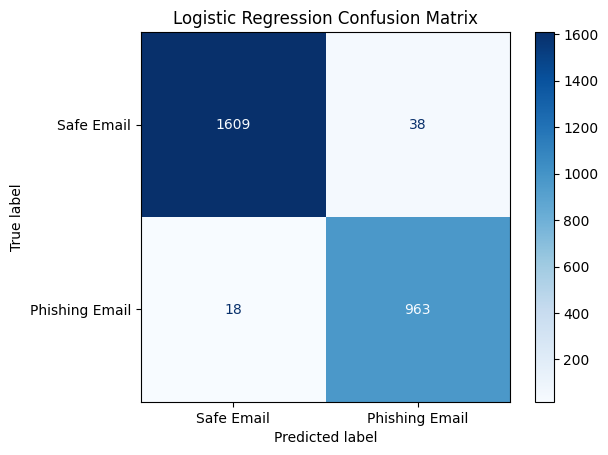

Confusion Matrix:
[[1609   38]
 [  18  963]]


In [12]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Safe Email", "Phishing Email"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


In [13]:

sample_email = """
Dear Customer,

Your bank account has been temporarily suspended.

You must verify your personal information
within 24 hours to avoid permanent account closure.

Click the link below to confirm your identity.
"""

sample_vector = vectorizer.transform(
    [sample_email]
)

prediction = model.predict(sample_vector)[0]

probability = model.predict_proba(
    sample_vector
)[0, 1]

print("Prediction:",
      "Phishing Email" if prediction == 1
      else "Safe Email")

print(
    "Phishing Probability:",
    round(probability * 100, 2), "%"
)


Prediction: Phishing Email
Phishing Probability: 97.86 %


In [14]:

import joblib

joblib.dump(
    model,
    "logistic_regression_model.pkl"
)

joblib.dump(
    vectorizer,
    "tfidf_vectorizer.pkl"
)

print("Model and vectorizer saved!")


Model and vectorizer saved!


In [1]:

import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected")


GPU available: True
GPU name: Tesla T4


In [3]:
import importlib.metadata as md

for package in ["pyarrow", "datasets", "transformers", "accelerate"]:
    try:
        print(package, md.version(package))
    except md.PackageNotFoundError:
        print(package, "Not installed")

pyarrow 26.0.0
datasets 5.1.0
transformers 5.20.2
accelerate 1.15.0


In [4]:
%pip install -q "pyarrow>=19,<24"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.1.0 requires pyarrow>=24.0.0, but you have pyarrow 23.0.1 which is incompatible.


In [5]:
%pip install -q --upgrade "datasets>=3.6,<4" "pyarrow>=19,<24" transformers accelerate evaluate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [1]:
%pip install -q "datasets>=3.6,<4" transformers accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [2]:

import datasets
import transformers
import accelerate
import torch

print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("GPU available:", torch.cuda.is_available())

print("All required libraries imported successfully!")


Datasets: 3.6.0
Transformers: 5.20.2
Accelerate: 1.15.0
GPU available: True
All required libraries imported successfully!


In [3]:

%pip check


ipython 7.34.0 requires jedi, which is not installed.
gcsfs 2025.12.0 has requirement fsspec==2025.12.0, but you have fsspec 2025.3.0.


In [4]:

from datasets import load_dataset
from sklearn.model_selection import train_test_split
import pandas as pd

dataset = load_dataset(
    "zefang-liu/phishing-email-dataset"
)

df = dataset["train"].to_pandas()

df = df[["Email Text", "Email Type"]].copy()

df.columns = ["text", "label"]

df["label"] = df["label"].map({
    "Safe Email": 0,
    "Phishing Email": 1
})

df = df.dropna(subset=["text", "label"])
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]
df = df.drop_duplicates(subset=["text"])
df["label"] = df["label"].astype(int)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


README.md:   0%|          | 0.00/616 [00:00<?, ?B/s]

Phishing_Email.csv: reconstructing file:   0%|          |  0.00B / 52.0MB            

Phishing_Email.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/18650 [00:00<?, ? examples/s]

Training: 12265
Validation: 2628
Testing: 2629


In [5]:

from transformers import AutoTokenizer

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    model_name
)

print("DistilBERT tokenizer loaded successfully!")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT tokenizer loaded successfully!


In [6]:

from datasets import Dataset

train_dataset = Dataset.from_pandas(
    train_df[["text", "label"]],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[["text", "label"]],
    preserve_index=False
)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=256
    )

train_tokenized = train_dataset.map(
    tokenize_function,
    batched=True
)

val_tokenized = val_dataset.map(
    tokenize_function,
    batched=True
)

print("Tokenization completed!")
print("Training samples:", len(train_tokenized))
print("Validation samples:", len(val_tokenized))


Map:   0%|          | 0/12265 [00:00<?, ? examples/s]

Map:   0%|          | 0/2628 [00:00<?, ? examples/s]

Tokenization completed!
Training samples: 12265
Validation samples: 2628


In [7]:

from transformers import AutoModelForSequenceClassification

bert_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2,
    id2label={
        0: "Safe Email",
        1: "Phishing Email"
    },
    label2id={
        "Safe Email": 0,
        "Phishing Email": 1
    }
)

print("DistilBERT model loaded successfully!")


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!


In [8]:

from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./distilbert_phishing",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1",
    greater_is_better=True,
    fp16=True,
    report_to="none",
    save_total_limit=2
)

print("Training configuration ready!")


Training configuration ready!


In [9]:

import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="binary",
            pos_label=1,
            zero_division=0
        )
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation metrics ready!")


Evaluation metrics ready!


In [10]:

from transformers import Trainer, DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer initialized successfully!")


Trainer initialized successfully!


In [11]:

train_result = trainer.train()

print("DistilBERT training completed!")


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.067291,0.072319,0.980974,0.972589,0.976555,0.974568
2,0.020482,0.077443,0.982116,0.977505,0.974516,0.976008


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT training completed!


In [12]:

results = trainer.evaluate()

print("DistilBERT Validation Results")

for metric, value in results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.020482,0.077443,2,0.982116,0.977505,0.974516,0.976008


DistilBERT Validation Results
eval_loss: 0.0774
eval_accuracy: 0.9821
eval_precision: 0.9775
eval_recall: 0.9745
eval_f1: 0.9760


In [13]:

trainer.save_model("./distilbert_phishing_final")

tokenizer.save_pretrained(
    "./distilbert_phishing_final"
)

print("DistilBERT model saved successfully!")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model saved successfully!


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train = vectorizer.fit_transform(train_df["text"])
X_test = vectorizer.transform(test_df["text"])

y_train = train_df["label"]
y_test = test_df["label"]

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train, y_train)

print("Logistic Regression retrained!")

Logistic Regression retrained!


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

lr_test_pred = lr_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, lr_test_pred)
lr_precision = precision_score(y_test, lr_test_pred)
lr_recall = recall_score(y_test, lr_test_pred)
lr_f1 = f1_score(y_test, lr_test_pred)

print("LOGISTIC REGRESSION — FINAL TEST RESULTS")
print("----------------------------------------")
print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1 Score:  {lr_f1:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        lr_test_pred,
        target_names=["Safe Email", "Phishing Email"]
    )
)

LOGISTIC REGRESSION — FINAL TEST RESULTS
----------------------------------------
Accuracy:  0.9772
Precision: 0.9592
Recall:    0.9807
F1 Score:  0.9698

Detailed Classification Report:
                precision    recall  f1-score   support

    Safe Email       0.99      0.98      0.98      1647
Phishing Email       0.96      0.98      0.97       982

      accuracy                           0.98      2629
     macro avg       0.97      0.98      0.98      2629
  weighted avg       0.98      0.98      0.98      2629



In [16]:
from datasets import Dataset

test_dataset = Dataset.from_pandas(
    test_df[["text", "label"]],
    preserve_index=False
)

test_tokenized = test_dataset.map(
    tokenize_function,
    batched=True
)

print("Test emails tokenized:", len(test_tokenized))

Map:   0%|          | 0/2629 [00:00<?, ? examples/s]

Test emails tokenized: 2629


In [17]:
bert_test_results = trainer.evaluate(
    eval_dataset=test_tokenized
)

print("DISTILBERT — FINAL TEST RESULTS")
print("--------------------------------")

print(
    f"Accuracy:  "
    f"{bert_test_results['eval_accuracy']:.4f}"
)

print(
    f"Precision: "
    f"{bert_test_results['eval_precision']:.4f}"
)

print(
    f"Recall:    "
    f"{bert_test_results['eval_recall']:.4f}"
)

print(
    f"F1 Score:  "
    f"{bert_test_results['eval_f1']:.4f}"
)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.020482,0.074889,2,0.982883,0.977574,0.976578,0.977076


DISTILBERT — FINAL TEST RESULTS
--------------------------------
Accuracy:  0.9829
Precision: 0.9776
Recall:    0.9766
F1 Score:  0.9771


In [18]:
comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "DistilBERT"
    ],
    "Accuracy": [
        lr_accuracy,
        bert_test_results["eval_accuracy"]
    ],
    "Precision": [
        lr_precision,
        bert_test_results["eval_precision"]
    ],
    "Recall": [
        lr_recall,
        bert_test_results["eval_recall"]
    ],
    "F1 Score": [
        lr_f1,
        bert_test_results["eval_f1"]
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,TF-IDF + Logistic Regression,0.977178,0.959163,0.980652,0.969789
1,DistilBERT,0.982883,0.977574,0.976578,0.977076


In [20]:

import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "DistilBERT"
    ],
    "Accuracy": [
        lr_accuracy,
        bert_test_results["eval_accuracy"]
    ],
    "Precision": [
        lr_precision,
        bert_test_results["eval_precision"]
    ],
    "Recall": [
        lr_recall,
        bert_test_results["eval_recall"]
    ],
    "F1 Score": [
        lr_f1,
        bert_test_results["eval_f1"]
    ]
})

display(comparison)


,Model,Accuracy,Precision,Recall,F1 Score
0,TF-IDF + Logistic Regression,0.977178,0.959163,0.980652,0.969789
1,DistilBERT,0.982883,0.977574,0.976578,0.977076


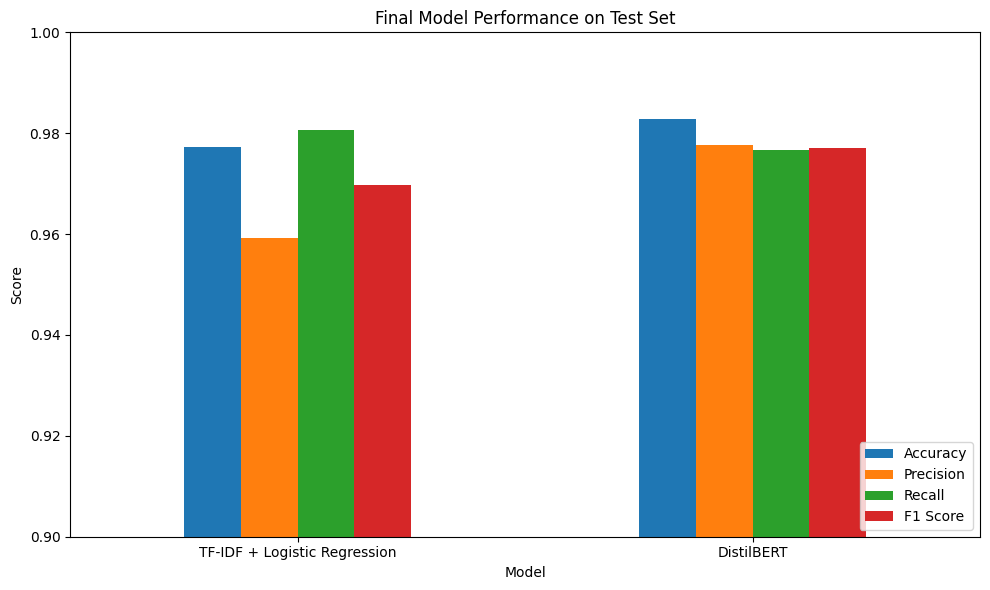

In [21]:

import matplotlib.pyplot as plt

comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Final Model Performance on Test Set")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0.90, 1.00)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [22]:

import numpy as np

bert_predictions = trainer.predict(test_tokenized)

bert_test_pred = np.argmax(
    bert_predictions.predictions,
    axis=1
)

print("DistilBERT predictions generated!")


DistilBERT predictions generated!


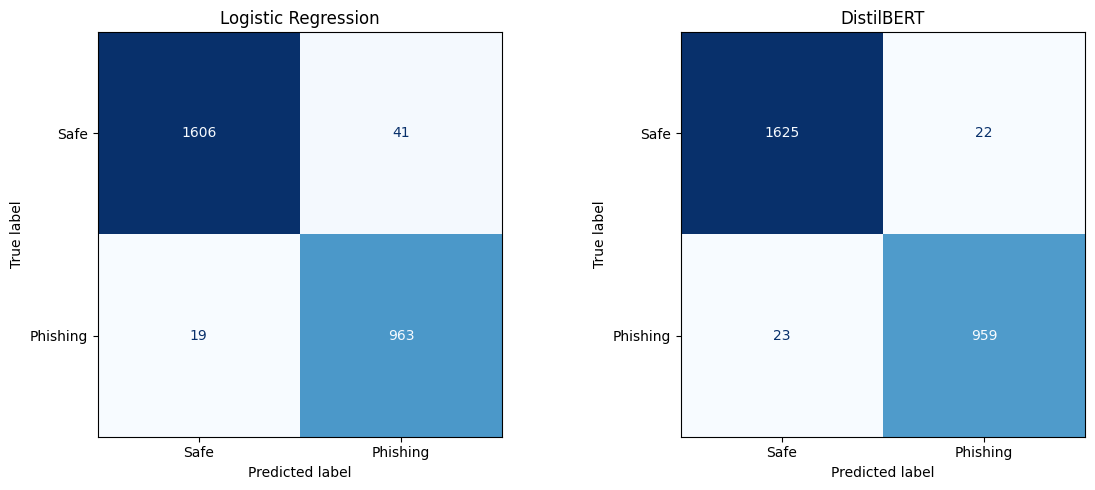

In [23]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_test_pred,
    display_labels=["Safe", "Phishing"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    bert_test_pred,
    display_labels=["Safe", "Phishing"],
    cmap="Blues",
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("DistilBERT")

plt.tight_layout()
plt.show()


In [24]:

error_analysis = test_df.reset_index(drop=True).copy()

error_analysis["LR Prediction"] = lr_test_pred
error_analysis["BERT Prediction"] = bert_test_pred

error_analysis["LR Correct"] = (
    error_analysis["label"] ==
    error_analysis["LR Prediction"]
)

error_analysis["BERT Correct"] = (
    error_analysis["label"] ==
    error_analysis["BERT Prediction"]
)

errors = error_analysis[
    ~error_analysis["BERT Correct"]
]

print("DistilBERT misclassified emails:", len(errors))

display(
    errors[
        ["text", "label", "BERT Prediction"]
    ].head(10)
)


DistilBERT misclassified emails: 45


,text,label,BERT Prediction
231,what everybody should know about dating,1,0
289,peter g [ tour dates ] tour dates friday 8 th ...,1,0
344,If you're an ISP or running a good size mail s...,0,1
391,The following domains that are registered as b...,0,1
516,message was created automatically by mail deli...,0,1
536,banner life upgraded to a + + effective februa...,1,0
541,as a promising energy professional . . . indus...,0,1
543,tomorrow ' s alert . homeland security technol...,1,0
596,"hello vince , nie bardzo wiem czy pisac po pol...",0,1
681,idea!This could also be a job for P2P; lots of...,0,1


In [25]:

import os
import joblib

# Save Logistic Regression and TF-IDF
os.makedirs("phishing_project", exist_ok=True)

joblib.dump(
    lr_model,
    "phishing_project/logistic_regression.pkl"
)

joblib.dump(
    vectorizer,
    "phishing_project/tfidf_vectorizer.pkl"
)

# Save DistilBERT and its tokenizer
trainer.save_model(
    "phishing_project/distilbert_model"
)

tokenizer.save_pretrained(
    "phishing_project/distilbert_model"
)

print("All models saved successfully!")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

All models saved successfully!


In [26]:

import shutil
from google.colab import files

shutil.make_archive(
    "phishing_project",
    "zip",
    "phishing_project"
)

files.download("phishing_project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:

%pip install -q streamlit


In [28]:

%%writefile phishing_project/app.py

import streamlit as st
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

st.set_page_config(
    page_title="PhishGuard AI",
    page_icon="🛡️",
    layout="centered"
)

st.title("🛡️ PhishGuard AI")
st.write("AI-Powered Phishing Email Detection Using NLP")

@st.cache_resource
def load_model():
    model_path = "phishing_project/distilbert_model"

    tokenizer = AutoTokenizer.from_pretrained(model_path)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_path
    )

    model.eval()

    return tokenizer, model

tokenizer, model = load_model()

email_text = st.text_area(
    "Paste your email content:",
    height=200,
    placeholder="Enter email subject and body..."
)

if st.button("Analyze Email", type="primary"):

    if not email_text.strip():
        st.warning("Please enter email content.")

    else:
        inputs = tokenizer(
            email_text,
            return_tensors="pt",
            truncation=True,
            max_length=256
        )

        with torch.no_grad():
            outputs = model(**inputs)

            probabilities = torch.softmax(
                outputs.logits,
                dim=1
            )[0]

        phishing_probability = probabilities[1].item()
        prediction = int(torch.argmax(probabilities).item())

        st.subheader("Analysis Result")

        if prediction == 1:
            st.error("⚠️ Phishing Email Detected")
        else:
            st.success("✅ Classified as Safe Email")

        st.metric(
            "Estimated Phishing Probability",
            f"{phishing_probability * 100:.2f}%"
        )

        st.progress(phishing_probability)

        st.caption(
            "This prediction is based on email text only. "
            "It does not verify links, attachments, "
            "or sender authenticity."
        )


Writing phishing_project/app.py


In [31]:

%%writefile phishing_project/app.py

import streamlit as st
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

st.set_page_config(
    page_title="PhishGuard AI",
    page_icon="🛡️",
    layout="centered"
)

st.title("🛡️ PhishGuard AI")
st.write("AI-Powered Phishing Email Detection Using NLP")

@st.cache_resource
def load_model():
    model_path = "phishing_project/distilbert_model"

    tokenizer = AutoTokenizer.from_pretrained(model_path)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_path
    )

    model.eval()

    return tokenizer, model

tokenizer, model = load_model()

email_text = st.text_area(
    "Paste your email content:",
    height=200,
    placeholder="Enter email subject and body..."
)

if st.button("Analyze Email", type="primary"):

    if not email_text.strip():
        st.warning("Please enter email content.")

    else:
        inputs = tokenizer(
            email_text,
            return_tensors="pt",
            truncation=True,
            max_length=256
        )

        with torch.no_grad():
            outputs = model(**inputs)

            probabilities = torch.softmax(
                outputs.logits,
                dim=1
            )[0]

        phishing_probability = probabilities[1].item()
        prediction = int(torch.argmax(probabilities).item())

        st.subheader("Analysis Result")

        if prediction == 1:
            st.error("⚠️ Phishing Email Detected")
        else:
            st.success("✅ Classified as Safe Email")

        st.metric(
            "Estimated Phishing Probability",
            f"{phishing_probability * 100:.2f}%"
        )

        st.progress(phishing_probability)

        st.caption(
            "This prediction is based on email text only. "
            "It does not verify links, attachments, "
            "or sender authenticity."
        )


Overwriting phishing_project/app.py
